In [5]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.linear_model import LinearRegression
from scipy.optimize import curve_fit

In [6]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [7]:
df = pd.read_csv('/content/drive/MyDrive/MOXVER2026/Data.csv', header=4)
df.head()

,Year,all fuels (utility-scale) Connecticut thousand megawatthours,coal Connecticut thousand megawatthours,natural gas Connecticut thousand megawatthours,wind Connecticut thousand megawatthours,all solar Connecticut thousand megawatthours,all fuels (utility-scale) Maine thousand megawatthours,coal Maine thousand megawatthours,natural gas Maine thousand megawatthours,wind Maine thousand megawatthours,...,all fuels (utility-scale) Alaska thousand megawatthours,coal Alaska thousand megawatthours,natural gas Alaska thousand megawatthours,wind Alaska thousand megawatthours,all solar Alaska thousand megawatthours,all fuels (utility-scale) Hawaii thousand megawatthours,coal Hawaii thousand megawatthours,natural gas Hawaii thousand megawatthours,wind Hawaii thousand megawatthours,all solar Hawaii thousand megawatthours
0,2025,43550.65985,0.00000,24460.30850,12.25000,2504.91104,14833.24156,31.77734,5564.79282,2874.18239,...,6442.86420,789.96237,2601.04065,129.98372,34.23341,9380.34867,NaN,NaN,573.43578,2608.23772
1,2024,44761.41240,0.00000,26036.34313,10.45000,1934.66613,14655.17750,29.37976,6398.78164,2446.24300,...,6690.50581,752.33678,3134.18572,123.36600,28.23252,9160.97898,NaN,NaN,663.39896,2278.11670
2,2023,40666.41848,0.00000,24952.02126,9.88853,1658.88086,12512.18100,43.20506,3975.03745,2338.71000,...,6717.82516,730.68146,3182.40710,111.36886,18.49755,9194.16430,NaN,NaN,634.22156,2040.24271
3,2022,43054.09924,0.00000,24530.68681,12.83308,1470.31565,12763.91983,42.44227,4140.36463,2716.38400,...,6694.12838,726.93403,3229.37601,139.27600,15.71979,9337.43375,647.75791,NaN,625.42187,1881.68869
4,2021,44079.94261,244.64713,24488.90155,12.75800,1128.64446,10908.14988,49.99624,3347.67249,2544.19700,...,6595.81806,752.89445,3085.39602,132.21200,12.25336,9182.19081,1084.55509,NaN,657.89100,1758.03099


In [8]:
df.shape

(25, 256)

In [9]:
df.columns = (
    df.columns
    .str.replace(" thousand megawatthours", "", regex=False)
    .str.strip()
)

In [10]:
long_df = df.melt(
    id_vars="Year",
    var_name="Fuel/State",
    value_name="Generation"
)

In [11]:
long_df

,Year,Fuel/State,Generation
0,2025,all fuels (utility-scale) Connecticut,43550.65985
1,2024,all fuels (utility-scale) Connecticut,44761.41240
2,2023,all fuels (utility-scale) Connecticut,40666.41848
3,2022,all fuels (utility-scale) Connecticut,43054.09924
4,2021,all fuels (utility-scale) Connecticut,44079.94261
...,...,...,...
6370,2005,all solar Hawaii,NaN
6371,2004,all solar Hawaii,NaN
6372,2003,all solar Hawaii,NaN
6373,2002,all solar Hawaii,NaN


In [12]:
states = [
    "Alabama", "Alaska", "Arizona", "Arkansas", "California", "Colorado",
    "Connecticut", "Delaware", "District Of Columbia", "Florida", "Georgia",
    "Hawaii", "Idaho", "Illinois", "Indiana", "Iowa", "Kansas", "Kentucky",
    "Louisiana", "Maine", "Maryland", "Massachusetts", "Michigan", "Minnesota",
    "Mississippi", "Missouri", "Montana", "Nebraska", "Nevada", "New Hampshire",
    "New Jersey", "New Mexico", "New York", "North Carolina", "North Dakota",
    "Ohio", "Oklahoma", "Oregon", "Pennsylvania", "Rhode Island",
    "South Carolina", "South Dakota", "Tennessee", "Texas", "Utah", "Vermont",
    "Virginia", "Washington", "West Virginia", "Wisconsin", "Wyoming"
]

In [13]:
def fuel_state(x):
    for state in sorted(states, key=len, reverse=True):
        if x.endswith(state):
            fuel = x[:-len(state)].strip()
            return pd.Series([fuel, state])
    return pd.Series([None, None])

long_df[["Fuel", "State"]] = long_df["Fuel/State"].apply(fuel_state)
long_df["Generation"] = pd.to_numeric(long_df["Generation"], errors="coerce")

unmatched = long_df.loc[long_df["State"].isna(), "Fuel/State"].unique()
print(unmatched)

[]


In [14]:
long_df["Generation"] = pd.to_numeric(long_df["Generation"])
long_df

,Year,Fuel/State,Generation,Fuel,State
0,2025,all fuels (utility-scale) Connecticut,43550.65985,all fuels (utility-scale),Connecticut
1,2024,all fuels (utility-scale) Connecticut,44761.41240,all fuels (utility-scale),Connecticut
2,2023,all fuels (utility-scale) Connecticut,40666.41848,all fuels (utility-scale),Connecticut
3,2022,all fuels (utility-scale) Connecticut,43054.09924,all fuels (utility-scale),Connecticut
4,2021,all fuels (utility-scale) Connecticut,44079.94261,all fuels (utility-scale),Connecticut
...,...,...,...,...,...
6370,2005,all solar Hawaii,NaN,all solar,Hawaii
6371,2004,all solar Hawaii,NaN,all solar,Hawaii
6372,2003,all solar Hawaii,NaN,all solar,Hawaii
6373,2002,all solar Hawaii,NaN,all solar,Hawaii


In [15]:
long_df['State'].nunique()

51

In [16]:
long_df['Fuel'].unique()

array(['all fuels (utility-scale)', 'coal', 'natural gas', 'wind',
       'all solar'], dtype=object)

In [17]:
final_df = long_df.set_index(["Year","State"]).sort_index()
final_df.drop(columns=["Fuel/State"], inplace=True)
final_df

Generation                       Fuel
Year State                                           
2001 Alabama  125345.11300  all fuels (utility-scale)
     Alabama   72198.11400                       coal
     Alabama    9612.68200                natural gas
     Alabama           NaN                       wind
     Alabama           NaN                  all solar
...                    ...                        ...
2025 Wyoming   46225.08347  all fuels (utility-scale)
     Wyoming   27024.11430                       coal
     Wyoming    4594.53129                natural gas
     Wyoming   12525.58352                       wind
     Wyoming     537.03917                  all solar

[6375 rows x 2 columns]

In [18]:
pivot = (
    long_df
    .pivot_table(
        index=["Year", "State"],
        columns="Fuel",
        values="Generation",
    )
    .reset_index()
)
pivot

Fuel,Year,State,all fuels (utility-scale),all solar,coal,natural gas,wind
0,2001,Alabama,125345.11300,NaN,72198.11400,9612.68200,NaN
1,2001,Alaska,6743.76600,NaN,564.59300,3895.56900,0.95000
2,2001,Arizona,89911.27200,NaN,40061.49400,12872.20000,NaN
3,2001,Arkansas,47192.03500,NaN,24764.47100,2706.90000,NaN
4,2001,California,198596.07500,NaN,2232.85100,111932.27100,3499.73800
...,...,...,...,...,...,...,...
1270,2025,Virginia,105953.63888,10153.59602,3606.93096,60695.78614,49.93300
1271,2025,Washington,103067.39997,1350.40246,3160.33788,16293.74311,8570.16969
1272,2025,West Virginia,53647.53754,343.56843,46635.59190,3314.04467,1991.26700
1273,2025,Wisconsin,66722.27721,4442.00398,23349.62800,23722.28680,1963.52449


In [19]:
pivot['Renewable'] = pivot['wind'].fillna(0) + pivot['all solar'].fillna(0)
pivot['coal'] = pivot['coal'].fillna(0) # Imporant got 24 states before -> 22 states after
pivot['%Renewable'] = (pivot['Renewable']/pivot['all fuels (utility-scale)']) * 100
pivot['%Coal'] = (pivot['coal']/pivot['all fuels (utility-scale)']) * 100
pivot

Fuel,Year,State,all fuels (utility-scale),all solar,coal,natural gas,wind,Renewable,%Renewable,%Coal
0,2001,Alabama,125345.11300,NaN,72198.11400,9612.68200,NaN,0.00000,0.000000,57.599465
1,2001,Alaska,6743.76600,NaN,564.59300,3895.56900,0.95000,0.95000,0.014087,8.372073
2,2001,Arizona,89911.27200,NaN,40061.49400,12872.20000,NaN,0.00000,0.000000,44.556698
3,2001,Arkansas,47192.03500,NaN,24764.47100,2706.90000,NaN,0.00000,0.000000,52.475955
4,2001,California,198596.07500,NaN,2232.85100,111932.27100,3499.73800,3499.73800,1.762239,1.124318
...,...,...,...,...,...,...,...,...,...,...
1270,2025,Virginia,105953.63888,10153.59602,3606.93096,60695.78614,49.93300,10203.52902,9.630183,3.404254
1271,2025,Washington,103067.39997,1350.40246,3160.33788,16293.74311,8570.16969,9920.57215,9.625325,3.066283
1272,2025,West Virginia,53647.53754,343.56843,46635.59190,3314.04467,1991.26700,2334.83543,4.352176,86.929604
1273,2025,Wisconsin,66722.27721,4442.00398,23349.62800,23722.28680,1963.52449,6405.52847,9.600285,34.995250


In [20]:
comp = pivot[["State","Year","Renewable","coal"]].copy()
comp['minus_coal'] = comp['Renewable'] - comp['coal']
comp['exceed_coal'] = comp['minus_coal'] > 0
comp
# False gives more coal used than renewable (wind + solar)
# True gives more renewable than coal

Fuel,State,Year,Renewable,coal,minus_coal,exceed_coal
0,Alabama,2001,0.00000,72198.11400,-72198.11400,False
1,Alaska,2001,0.95000,564.59300,-563.64300,False
2,Arizona,2001,0.00000,40061.49400,-40061.49400,False
3,Arkansas,2001,0.00000,24764.47100,-24764.47100,False
4,California,2001,3499.73800,2232.85100,1266.88700,True
...,...,...,...,...,...,...
1270,Virginia,2025,10203.52902,3606.93096,6596.59806,True
1271,Washington,2025,9920.57215,3160.33788,6760.23427,True
1272,West Virginia,2025,2334.83543,46635.59190,-44300.75647,False
1273,Wisconsin,2025,6405.52847,23349.62800,-16944.09953,False


In [21]:
pivot_yrs = (
    comp[comp['exceed_coal']]
    .groupby("State")["Year"]
    .min()
    .rename("Piv Year")
    .reset_index()
)
pivot_yrs

,State,Piv Year
0,Arizona,2023
1,California,2001
2,Colorado,2023
3,Connecticut,2016
4,Delaware,2019
5,District Of Columbia,2014
6,Florida,2023
7,Hawaii,2017
8,Idaho,2006
9,Illinois,2024


In [22]:
# Creating set to check the states than surpassed coal fuel_type
all_states = set(pivot["State"].unique())
cross = set(pivot_yrs["State"])
print(all_states - cross)

{'Michigan', 'Mississippi', 'North Carolina', 'Pennsylvania', 'Montana', 'South Carolina', 'Arkansas', 'Ohio', 'Georgia', 'Nebraska', 'Alabama', 'Wisconsin', 'Utah', 'Kentucky', 'Tennessee', 'Indiana', 'West Virginia', 'Wyoming', 'Louisiana', 'North Dakota', 'Missouri', 'Alaska'}


In [23]:
print(len(all_states - cross))
# 22 states still have more coal generation than renewable!!!

22


In [24]:
state = "Washington"
selection = pivot[pivot['State'] == state].sort_values("Year")
selection

Fuel,Year,State,all fuels (utility-scale),all solar,coal,natural gas,wind,Renewable,%Renewable,%Coal
47,2001,Washington,83048.66900,NaN,9082.35800,9374.24500,NaN,0.00000,0.000000,10.936187
98,2002,Washington,102765.04800,NaN,8660.80500,4719.31100,416.58100,416.58100,0.405372,8.427773
149,2003,Washington,100094.69100,NaN,11089.79600,7082.60500,603.67400,603.67400,0.603103,11.079305
200,2004,Washington,102165.05213,NaN,10409.33056,8468.80006,736.57602,736.57602,0.720967,10.188739
251,2005,Washington,101965.85033,NaN,10494.40740,8578.54553,498.47000,498.47000,0.488860,10.292081
302,2006,Washington,108203.15532,NaN,6372.82292,7495.40984,1037.65100,1037.65100,0.958984,5.889683
353,2007,Washington,106990.21654,NaN,8556.81645,7287.39375,2437.82300,2437.82300,2.278548,7.997756
404,2008,Washington,110828.45104,NaN,8761.64415,9809.35393,3657.48429,3657.48429,3.300131,7.905591
455,2009,Washington,104470.13259,NaN,7477.77277,11971.14095,3572.48556,3572.48556,3.419624,7.157809
506,2010,Washington,103472.72898,NaN,8526.93250,10359.23535,4744.67851,4744.67851,4.585439,8.240753


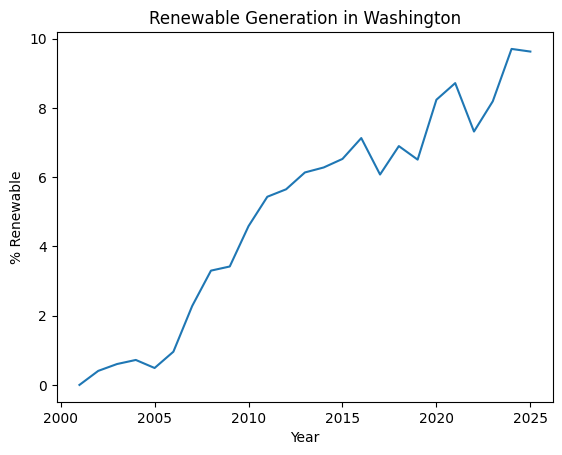

In [25]:
plt.plot(selection["Year"], selection["%Renewable"])
plt.title(f"Renewable Generation in {state}")
plt.xlabel("Year")
plt.ylabel("% Renewable")
plt.show()

In [26]:
# something to flag that District Of Columbia has 200% Renewable energy and this is actual the true data from EIA but there is one possible explanation: "all fuels (utility scale)" counts large scale power plants but the solar
# columns counts small scale and distributed solar which is tracked seperately from utility-scale total

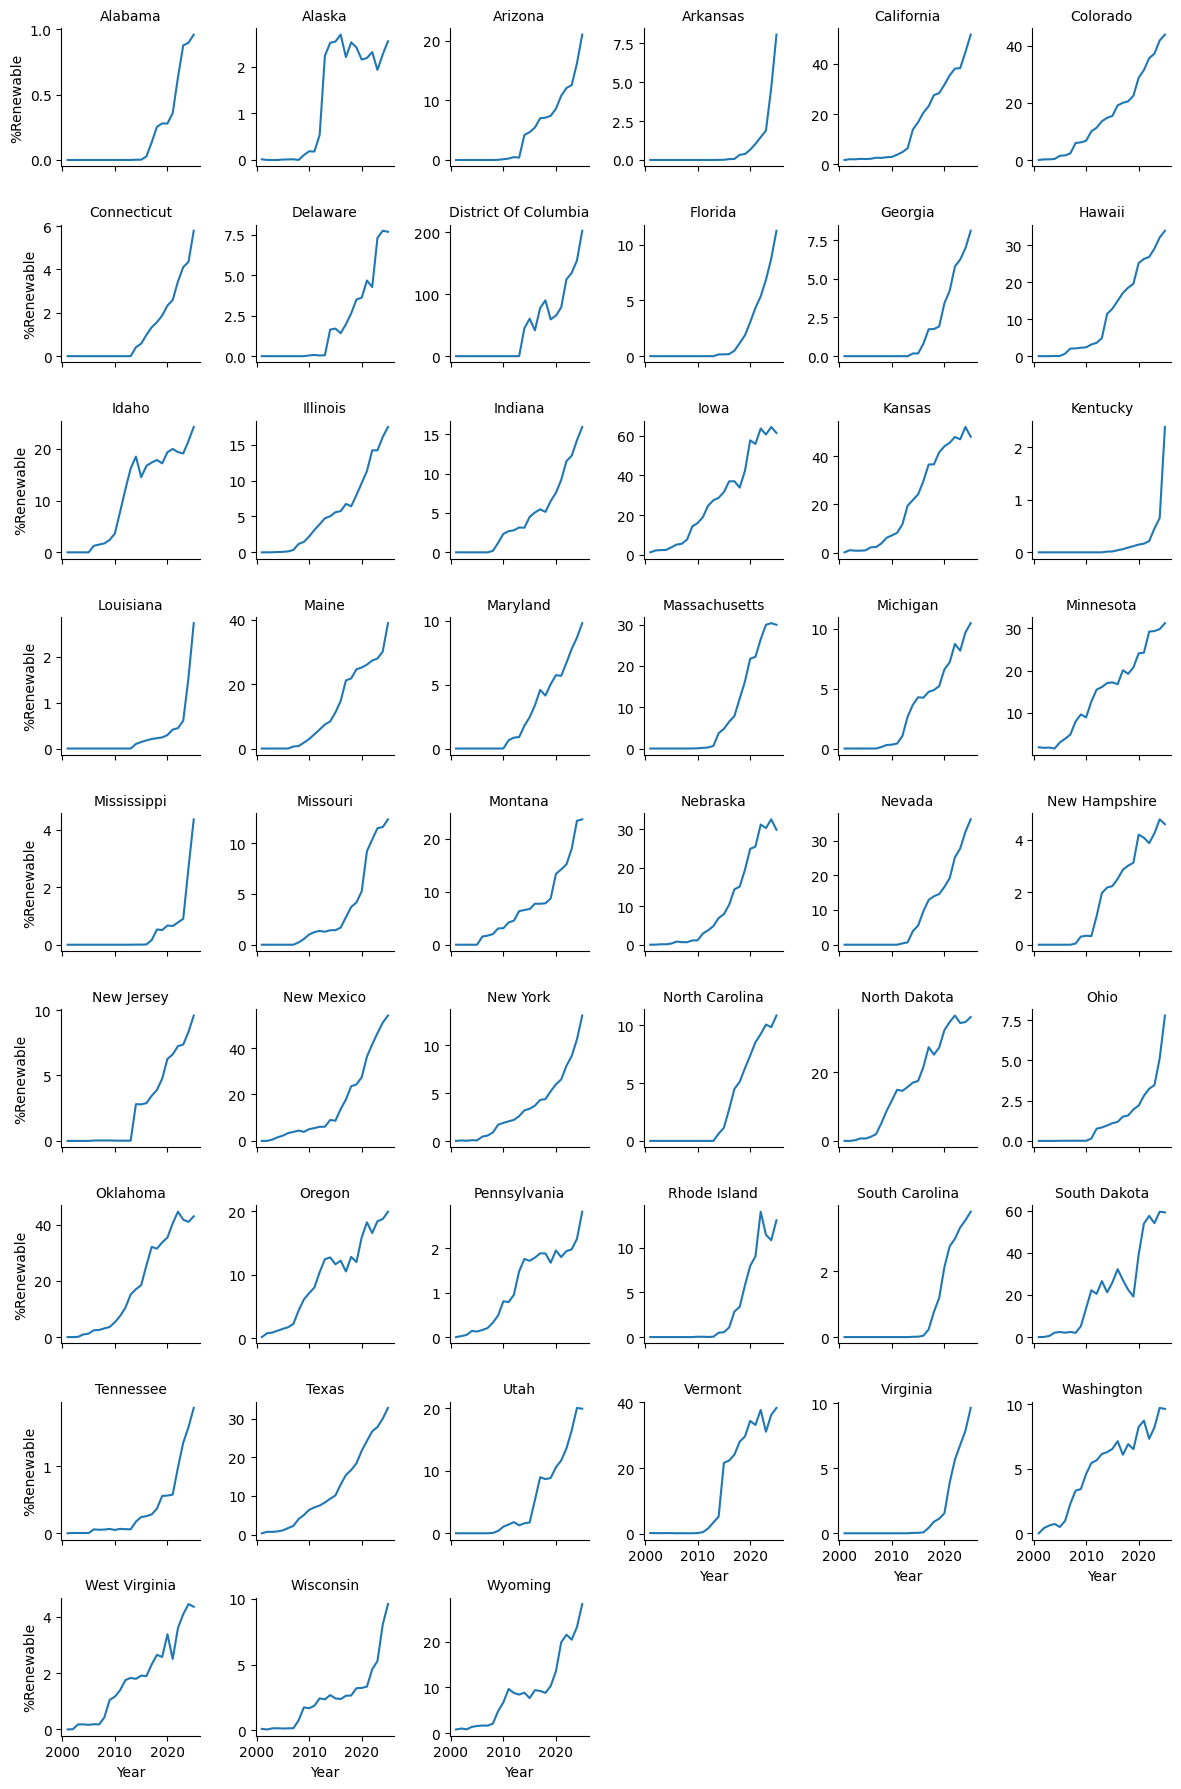

In [27]:
g = sns.FacetGrid(pivot, col="State", col_wrap = 6, height = 2, sharey = False)
g.map_dataframe(sns.lineplot, x="Year", y="%Renewable")
g.set_titles("{col_name}")
plt.show()

In [28]:
row_trends = []
for state, group in pivot.groupby("State"):
  group = group.dropna(subset=["%Renewable"]).sort_values("Year")

  x = group[["Year"]].values
  y = group[["%Renewable"]].values

  model = LinearRegression()
  model.fit(x,y)

  row_trends.append({
      "State": state,
      "Trend": model.coef_[0],
      "lastest%": y[-1],
      "lastestYear": x[-1][0]
  })
trending_df = pd.DataFrame(row_trends)
trending_df

,State,Trend,lastest%,lastestYear
0,Alabama,[0.03403689615771339],[0.9594382256324809],2025
1,Alaska,[0.13662667923284127],[2.5488218423104434],2025
2,Arizona,[0.7285024998295171],[21.01563064794916],2025
3,Arkansas,[0.15143418688827404],[8.061642984267056],2025
4,California,[2.058017832963995],[51.659970831999935],2025
5,Colorado,[1.8434779235055125],[43.86823407520984],2025
6,Connecticut,[0.19626008466817424],[5.779845928097918],2025
7,Delaware,[0.3092544210096214],[7.674289348851528],2025
8,District Of Columbia,[6.97605295814273],[202.0408085741047],2025
9,Florida,[0.32611700745424116],[11.251157629580462],2025


In [59]:
def intersection_year(r, cap=2100):
  slope = r["Trend"]
  if r["lastest%"] >= 100:
    return r["lastest%"], "Already past 100%"
  if slope <=0:
    return None, "No trend of renewable energies"
  years = (100-r["lastest%"]) / slope
  predict = r["lastestYear"] + years
  return predict, "Predicted"
trending_df[["Intersection_Year","fg"]] = trending_df.apply(lambda x: pd.Series(intersection_year(x)), axis=1)
trending_df.sort_values("Intersection_Year")
trending_df

,State,Trend,lastest%,lastestYear,Intersection_Year,fg
0,Alabama,[0.03403689615771339],[0.9594382256324809],2025,[4934.800039211951],Predicted
1,Alaska,[0.13662667923284127],[2.5488218423104434],2025,[2738.2660963794033],Predicted
2,Arizona,[0.7285024998295171],[21.01563064794916],2025,[2133.4201761428885],Predicted
3,Arkansas,[0.15143418688827404],[8.061642984267056],2025,[2632.11757962265],Predicted
4,California,[2.058017832963995],[51.659970831999935],2025,[2048.488634740536],Predicted
5,Colorado,[1.8434779235055125],[43.86823407520984],2025,[2055.448840861653],Predicted
6,Connecticut,[0.19626008466817424],[5.779845928097918],2025,[2505.0780262130447],Predicted
7,Delaware,[0.3092544210096214],[7.674289348851528],2025,[2323.5428966536133],Predicted
8,District Of Columbia,[6.97605295814273],[202.0408085741047],2025,[202.0408085741047],Already past 100%
9,Florida,[0.32611700745424116],[11.251157629580462],2025,[2297.138037397121],Predicted


In [60]:
type(trending_df.iloc[0, 5])

str

In [61]:
trending_df["Intersection_Year"] = trending_df["Intersection_Year"].apply(
    lambda x: x[0] if hasattr(x, "__len__") else x
)

In [62]:
alr_flag = trending_df[trending_df["Intersection_Year"] == 2100]
complete_df =  trending_df[trending_df["fg"] == "Predicted"]
len(complete_df)

50

In [64]:
top_5 = complete_df.sort_values("Intersection_Year").head(5)
bottom_5 = complete_df.sort_values("Intersection_Year").tail(5)

In [65]:
top_5

,State,Trend,lastest%,lastestYear,Intersection_Year,fg
15,Iowa,[2.971044404406448],[61.4143034434759],2025,2037.987250,Predicted
41,South Dakota,[2.6336432627936346],[59.17663157485896],2025,2040.500721,Predicted
16,Kansas,[2.5451857914632647],[48.112501533054065],2025,2045.386527,Predicted
31,New Mexico,[2.1366901046927036],[54.02416211190385],2025,2046.517317,Predicted
4,California,[2.058017832963995],[51.659970831999935],2025,2048.488635,Predicted


In [66]:
bottom_5

,State,Trend,lastest%,lastestYear,Intersection_Year,fg
24,Mississippi,[0.08771472144798395],[4.36266118160302],2025,3115.322551,Predicted
42,Tennessee,[0.05896390027039084],[1.8680874282049196],2025,3689.271056,Predicted
18,Louisiana,[0.05341265595248208],[2.7304964451254237],2025,3846.094679,Predicted
17,Kentucky,[0.035512637261457036],[2.3833670661681667],2025,4773.785797,Predicted
0,Alabama,[0.03403689615771339],[0.9594382256324809],2025,4934.800039,Predicted


In [36]:
#Since the bottom_5 states have an extreme 'Intersection_Year' any forecast after 2100 should be taken with a grain of salt.

In [37]:
less_2100 = complete_df[complete_df["Intersection_Year"] <= 2100].sort_values("Intersection_Year")
len(less_2100)

18

In [38]:
less_2100

,State,Trend,lastest%,lastestYear,Intersection_Year,fg
15,Iowa,[2.971044404406448],[61.4143034434759],2025,2037.987250,Predicted
41,South Dakota,[2.6336432627936346],[59.17663157485896],2025,2040.500721,Predicted
16,Kansas,[2.5451857914632647],[48.112501533054065],2025,2045.386527,Predicted
31,New Mexico,[2.1366901046927036],[54.02416211190385],2025,2046.517317,Predicted
4,California,[2.058017832963995],[51.659970831999935],2025,2048.488635,Predicted
36,Oklahoma,[2.192960416922243],[42.937185972719654],2025,2051.020905,Predicted
5,Colorado,[1.8434779235055125],[43.86823407520984],2025,2055.448841,Predicted
45,Vermont,[1.9422919205722395],[38.30603721342862],2025,2056.763486,Predicted
34,North Dakota,[1.7954940437988287],[36.175681392873656],2025,2060.546940,Predicted
19,Maine,[1.6022335493277433],[38.870198173999135],2025,2063.152866,Predicted


In [45]:
latest = (
    pivot.sort_values("Year")
    .groupby("State")
    .tail(1)[["State", "%Renewable", "%Coal", "Year"]]
    .rename(columns={"Year": "Latest Year"})
)
latest

Fuel,State,%Renewable,%Coal,Latest Year
1259,Ohio,7.794886,24.322539,2025
1260,Oklahoma,42.937186,10.357571,2025
1256,New York,13.094331,0.000000,2025
1255,New Mexico,54.024162,20.888970,2025
1253,New Hampshire,4.592224,1.238334,2025
1252,Nevada,36.105652,5.747590,2025
1251,Nebraska,29.904055,45.592752,2025
1250,Montana,23.677070,35.167919,2025
1249,Missouri,12.329569,63.724582,2025
1248,Mississippi,4.362661,5.351869,2025


In [70]:
report_card = latest.merge(pivot_yrs, on="State", how="left")
report_card = report_card.merge(
    trending_df[["State", "Trend", "Intersection_Year", "fg"]],
    on="State",
    how="left"
)

legislated = {
    "California": 2045, "Hawaii": 2045, "New Mexico": 2045, "Washington": 2045,
    "Nevada": 2050, "Maine": 2050, "New York": 2040, "Minnesota": 2040,
    "Oregon": 2040, "Michigan": 2040, "Connecticut": 2040, "Rhode Island": 2033,
    "Virginia": 2045, "Colorado": 2040, "Illinois": 2050,
    "North Carolina": 2050, "Nebraska": 2050, "District Of Columbia": 2040,
    "New Jersey": 2050
}

report_card["Legialated_Target"] = report_card["State"].map(legislated)
report_card

,State,%Renewable,%Coal,Latest Year,Piv Year,Trend,Intersection_Year,fg,Legialated_Target
0,Ohio,7.794886,24.322539,2025,NaN,[0.21748572573435923],2448.959381,Predicted,NaN
1,Oklahoma,42.937186,10.357571,2025,2016.0,[2.192960416922243],2051.020905,Predicted,NaN
2,New York,13.094331,0.000000,2025,2015.0,[0.44979797521757797],2218.210450,Predicted,2040.0
3,New Mexico,54.024162,20.888970,2025,2021.0,[2.1366901046927036],2046.517317,Predicted,2045.0
4,New Hampshire,4.592224,1.238334,2025,2016.0,[0.2323739637158057],2435.578596,Predicted,NaN
5,Nevada,36.105652,5.747590,2025,2016.0,[1.397620793045224],2070.716512,Predicted,2050.0
6,Nebraska,29.904055,45.592752,2025,NaN,[1.4998381754568022],2071.735672,Predicted,2050.0
7,Montana,23.677070,35.167919,2025,NaN,[0.8974387284478416],2110.045282,Predicted,NaN
8,Missouri,12.329569,63.724582,2025,NaN,[0.4974345308263275],2201.245166,Predicted,NaN
9,Mississippi,4.362661,5.351869,2025,NaN,[0.08771472144798395],3115.322551,Predicted,NaN


In [75]:
def grade_build(gpa):
  return (gpa -gpa.min()) / (gpa.max() - gpa.min())
report_card["adopt_score"] = grade_build(report_card["%Renewable"])
report_card["speed"] = grade_build(report_card["Trend"])
report_card["total_score"] = (0.5*report_card["adopt_score"]) + (0.5*report_card["speed"])
report_card["percentile"] = report_card["total_score"].rank(pct=True)

def grade_assign(g):
  if g >= 0.9: return "A"
  elif g >= 0.75: return "B"
  elif g >= 0.5: return "C"
  elif g >= 0.2: return "D"
  else: return "F"

report_card.to_csv("/content/drive/MyDrive/MOXVER2026/report_card.csv", index=False)
pivot.to_csv("/content/drive/MyDrive/MOXVER2026/pivot.csv", index=False)
report_card["Grade"] = report_card["percentile"].apply(grade_assign)
report_card.sort_values("total_score", ascending=False)
report_card

,State,%Renewable,%Coal,Latest Year,Piv Year,Trend,Intersection_Year,fg,Legialated_Target,adopt_score,speed,total_score,percentile,Grade
0,Ohio,7.794886,24.322539,2025,NaN,[0.21748572573435923],2448.959381,Predicted,NaN,0.033993,[0.026425872244984418],[0.030209657541091135],0.254902,D
1,Oklahoma,42.937186,10.357571,2025,2016.0,[2.192960416922243],2051.020905,Predicted,NaN,0.208760,[0.3109937374802331],[0.25987687091122796],0.882353,B
2,New York,13.094331,0.000000,2025,2015.0,[0.44979797521757797],2218.210450,Predicted,2040.0,0.060348,[0.059890538331739455],[0.06011935370370725],0.470588,D
3,New Mexico,54.024162,20.888970,2025,2021.0,[2.1366901046927036],2046.517317,Predicted,2045.0,0.263897,[0.3028879780398769],[0.2833923733837178],0.921569,A
4,New Hampshire,4.592224,1.238334,2025,2016.0,[0.2323739637158057],2435.578596,Predicted,NaN,0.018066,[0.028570528472874113],[0.023318388673076628],0.196078,F
5,Nevada,36.105652,5.747590,2025,2016.0,[1.397620793045224],2070.716512,Predicted,2050.0,0.174786,[0.19642476835433947],[0.185605398069265],0.764706,B
6,Nebraska,29.904055,45.592752,2025,NaN,[1.4998381754568022],2071.735672,Predicted,2050.0,0.143945,[0.21114922037215142],[0.17754700847304125],0.745098,C
7,Montana,23.677070,35.167919,2025,NaN,[0.8974387284478416],2110.045282,Predicted,NaN,0.112977,[0.124373355604603],[0.11867533138854242],0.627451,C
8,Missouri,12.329569,63.724582,2025,NaN,[0.4974345308263275],2201.245166,Predicted,NaN,0.056545,[0.06675260191433627],[0.06164876172471982],0.490196,D
9,Mississippi,4.362661,5.351869,2025,NaN,[0.08771472144798395],3115.322551,Predicted,NaN,0.016925,[0.007732310730914933],[0.012328458337813344],0.137255,F


In [72]:
fuel_types = pivot[pivot["Year"].isin([2014, 2024])][
    ["State", "Year", "all fuels (utility-scale)", "coal", "natural gas", "wind", "all solar"]
].copy()
for col in ["coal", "natural gas", "wind", "all solar"]:
    fuel_types[col] = fuel_types[col].fillna(0)
fuel_types["other"] = (
    fuel_types["all fuels (utility-scale)"]
    - fuel_types["coal"]
    - fuel_types["natural gas"]
    - fuel_types["wind"]
    - fuel_types["all solar"]
)
fuel_types["other"] = fuel_types["other"].clip(lower=0)
fuel_types_1 = fuel_types.melt(
    id_vars=["State", "Year"],
    value_vars=["coal", "natural gas", "wind", "all solar", "other"],
    var_name="Fuel",
    value_name="Generation"
)
fuel_types_1.to_csv(
    "/content/drive/MyDrive/MOXVER2026/fuel_mix_2014_2024.csv", index=False
)
fuel_types_1

,State,Year,Fuel,Generation
0,Alabama,2014,coal,47301.62625
1,Alaska,2014,coal,558.29218
2,Arizona,2014,coal,42665.01057
3,Arkansas,2014,coal,33220.75479
4,California,2014,coal,804.75957
...,...,...,...,...
505,Virginia,2024,other,31635.82816
506,Washington,2024,other,71519.37102
507,West Virginia,2024,other,1464.99296
508,Wisconsin,2024,other,13023.97701
